# Fine-tune Simons

Fine-tune [Simons-25M](https://huggingface.co/abel-lab/Simons-25M) on synthetic daily sales,
then compare forecasts on new stores. The [guide](../docs/GETTING_STARTED.md#fine-tune) covers your
own data.

Run from a repository checkout after `pip install -e . matplotlib`.
Allow about 13 GB of memory on GPU or 14 GB on CPU. Runtime depends on your hardware.

Work from the repository root, with one folder for the data, run, and exported model.

In [1]:
import json
import os
import shutil
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pyarrow as pa
import pyarrow.parquet as pq
import torch
import yaml
from huggingface_hub import snapshot_download

from simons import Simons, forecast_series

if not Path("configs").is_dir():
    os.chdir("..")  # the notebook's folder is examples/
work = Path("runs/finetune-notebook")
device = "cuda" if torch.cuda.is_available() else "cpu"

## The data

Generate 200 training stores with 400 to 799 days of sales. Each store has a weekly cycle and
payday bumps within a four-week cycle, with its own level and bump size. Evaluate on 40 new
stores using 42 days of history to forecast the next 28 days.

In [2]:
rng = np.random.default_rng(0)
H = 28  # forecast horizon: four weeks
HISTORY = 42  # history of a new store: six weeks
payday = np.zeros(28)
payday[[0, 1, 2, 14, 15]] = 1.0, 0.7, 0.3, 0.5, 0.3  # the bumps of the four-week cycle


def store(days):
    t = rng.integers(28) + np.arange(days)  # the store opens on any day of the cycle
    level = rng.uniform(50, 200) * (1 + rng.uniform(-0.2, 0.4) * np.arange(days) / 700)
    weekly = 1 + 0.2 * np.sin(2 * np.pi * t / 7) + 0.15 * (t % 7 >= 5)
    bump = 1 + rng.uniform(0.4, 0.8) * payday[t % 28]
    return (level * weekly * bump * rng.lognormal(0, 0.08, days)).astype(np.float32)


train = [store(rng.integers(400, 800)) for _ in range(200)]
test = [store(HISTORY + H) for _ in range(40)]  # the last H days are the test period

The training code reads a corpus folder of `train-*.parquet` files with one row per series. `target`
is `[variate][time]`, here one variate.

In [3]:
rows = [{"item_id": f"store-{i}", "source": "my-sales", "freq": "D", "target": [y]}
        for i, y in enumerate(train)]
(work / "data").mkdir(parents=True, exist_ok=True)
pq.write_table(pa.Table.from_pylist(rows), work / "data/train-my-sales.parquet")

## The base model

Measure the released model first: forecast the test period of the new stores and score it with the
weighted quantile loss (WQL, lower is better) over the 9 quantiles.

In [4]:
LEVELS = np.arange(1, 10) / 10
actual = np.stack([y[-H:] for y in test])  # [store, H]


def forecast(model):
    """Quantile forecasts of the test period, [store, H, 9]."""
    return np.stack(forecast_series(model, [y[:-H] for y in test], horizon=H))


def wql(quantiles, axis=None):
    """WQL over all stores, or per store with axis=1."""
    diff = actual[..., None] - quantiles
    loss = np.maximum(LEVELS * diff, (LEVELS - 1) * diff).mean(-1)
    return 2 * loss.sum(axis) / np.abs(actual).sum(axis)


base = forecast(Simons.from_pretrained("abel-lab/Simons-25M", device=device))
print(f"base model: WQL {wql(base):.4f}")

base model: WQL 0.0779


## The config

A fine-tune runs the recipe's last stage from the released weights. Start from the stage-4 config of
the model's size and replace the training keys below.

In [5]:
config = yaml.safe_load(Path("configs/simons-25m-stage4.yaml").read_text())
config["training"].update(
    # The released weights (a model folder) and your corpus
    warm_start=snapshot_download("abel-lab/Simons-25M",
                                 allow_patterns=["config.json", "model.safetensors"]),
    data=str(work / "data"),
    covariate_data=None,  # no corpus of known-future covariates
    long_weight=0,
    # One phase at the model's full context, from step 0
    context_schedule=None, synthetic_only_stages=0, warm_start_stage=0, warm_start_step=None,
    far_from_stage=0, stitch_from_stage=0,
    # Learning rate: a quarter of the peak after a short warmup, then a linear decay to 0
    lr_schedule="linear", warm_lr_scale=0.25, rewarm_from=0.1, rewarm_steps=5,
    # A short plan with small batches, so that it also runs on a CPU. A batch of 32 windows is one
    # packed row: too few for the config's synthetic rows, which a full run (batch_size 784) keeps
    steps=60, batch_size=32, loader_workers=0,
    covariate_tokens=512, covariate_max_batch=8, checkpoint_blocks=0,
)
with open(work / "finetune.yaml", "w") as file:
    yaml.safe_dump(config, file, sort_keys=False)

## Train and export

Train the model and export it for forecasting.

In [6]:
def training(*args):
    """Run `python -m simons.training <args>`."""
    done = subprocess.run([sys.executable, "-m", "simons.training", *args],
                          capture_output=True, text=True)
    if done.returncode:
        raise RuntimeError(done.stderr[-2000:])


shutil.rmtree(work / "run", ignore_errors=True)  # train needs an empty output folder
training("train", "--config", str(work / "finetune.yaml"), "--output", str(work / "run"))
training("export", "--checkpoint", str(work / "run/checkpoint.pt"), "--output", str(work / "model"))
run = json.loads((work / "run/run.json").read_text())
print(f"{run['steps']} steps in {run['elapsed_seconds']:.0f} s on {device}")

60 steps in 4 s on cuda


## Compare

The same forecast with the fine-tuned model.

In [7]:
tuned = forecast(Simons.from_pretrained(work / "model", device=device))
print(f"base model: WQL {wql(base):.4f}")
print(f"fine-tuned: WQL {wql(tuned):.4f} ({wql(tuned) / wql(base) - 1:+.0%})")
before, after = wql(base, axis=1), wql(tuned, axis=1)
print(f"lower WQL on {(after < before).sum()} of the {len(test)} stores")

base model: WQL 0.0779
fine-tuned: WQL 0.0604 (-22%)
lower WQL on 40 of the 40 stores


Compare WQL across the 40 test stores. The plots show the three largest improvements.

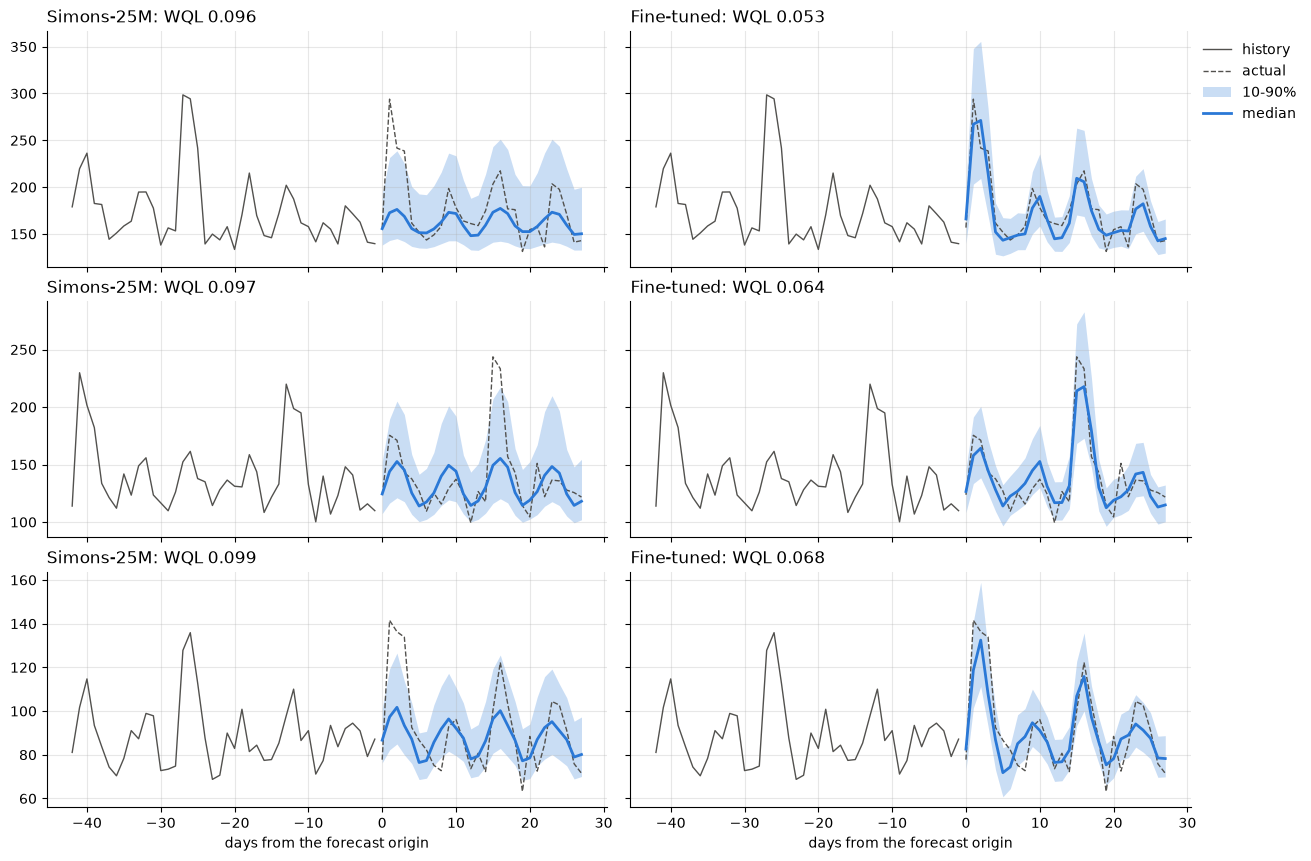

In [8]:
def plot_forecast(ax, y, q, title):
    ahead = np.arange(H)
    ax.plot(np.arange(-HISTORY, 0), y[:-H], color="#52514e", lw=1, label="history")
    ax.plot(ahead, y[-H:], color="#52514e", lw=1, ls="--", label="actual")
    ax.fill_between(ahead, q[:, 0], q[:, -1], color="#2a78d6", alpha=0.25, lw=0, label="10-90%")
    ax.plot(ahead, q[:, 4], color="#2a78d6", lw=2, label="median")
    ax.set_title(title, loc="left")
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)


fig, axes = plt.subplots(3, 2, figsize=(13, 8.5), sharex=True, sharey="row",
                         constrained_layout=True)
for row, i in zip(axes, np.argsort(after - before)[:3]):
    plot_forecast(row[0], test[i], base[i], f"Simons-25M: WQL {before[i]:.3f}")
    plot_forecast(row[1], test[i], tuned[i], f"Fine-tuned: WQL {after[i]:.3f}")
for ax in axes[-1]:
    ax.set_xlabel("days from the forecast origin")
axes[0, 1].legend(loc="upper left", bbox_to_anchor=(1, 1), frameon=False)
plt.show()

## Your own data

Replace the synthetic stores with your series, keeping the test period out of training.
The [guide](../docs/GETTING_STARTED.md#fine-tune) covers optional covariates, configuration, and
model export.